# Rossmann Daily Sales Forecasting

**Midterm project — ML Zoomcamp 2026**

Predict daily sales for 1,115 Rossmann stores from calendar, promotion, holiday, and static store features.

**Business question:** given a store and a date, what daily sales should we expect?

**Metric:** RMSE and MAE on open store-days, evaluated on a future month the model never saw. The store-median baseline is the floor.

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib-cache")
os.environ.setdefault("IPYTHONDIR", "/tmp/ipython")

import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from model import CATEGORICAL_FEATURES, FEATURES, NUMERIC_FEATURES

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

df = pd.read_parquet("data/processed/rossmann.parquet")
feature_metadata = json.loads(Path("models/feature_metadata.json").read_text())
for column in CATEGORICAL_FEATURES:
    df[column] = pd.Categorical(df[column], categories=feature_metadata["categories"][column])
df.head()

,date,sales,split,store,state_holiday,store_type,assortment,promo_interval,day_of_week,promo,...,promo2_open_months,year,month,day,week_of_year,day_of_year,is_month_start,is_month_end,is_weekend,days_to_christmas
0,2015-07-31,5263,test,1,0,c,a,None,4,1,...,NaN,2015,7,31,31,212,0,1,0,147
1,2015-07-31,6064,test,2,0,a,a,"Jan,Apr,Jul,Oct",4,1,...,63.981588,2015,7,31,31,212,0,1,0,147
2,2015-07-31,8314,test,3,0,a,a,"Jan,Apr,Jul,Oct",4,1,...,51.783659,2015,7,31,31,212,0,1,0,147
3,2015-07-31,13995,test,4,0,c,c,None,4,1,...,NaN,2015,7,31,31,212,0,1,0,147
4,2015-07-31,4822,test,5,0,a,a,None,4,1,...,NaN,2015,7,31,31,212,0,1,0,147


## 1. What is in the data?

`prepare_data.py` filters closed and zero-sales days, so every row is an open store-day. The split column is temporal: train before June 2015, validation June, test July.

In [2]:
print(f"rows: {len(df):,}")
print(f"date range: {df.date.min().date()} -> {df.date.max().date()}")
print(df.split.value_counts().to_string())
df[["sales", "promo", "day_of_week"]].describe().round(1)

rows: 844,338
date range: 2013-01-01 -> 2015-07-31
split
train         785727
test           30188
validation     28423


,sales,promo,day_of_week
count,844338.0,844338.0,844338.0
mean,6956.0,0.4,2.5
std,3103.8,0.5,1.7
min,46.0,0.0,0.0
25%,4859.0,0.0,1.0
50%,6369.0,0.0,2.0
75%,8360.0,1.0,4.0
max,41551.0,1.0,6.0


### Target distribution

Sales are right-skewed: a long tail of high-volume store-days. RMSE is the right metric because large misses are expensive for staffing.

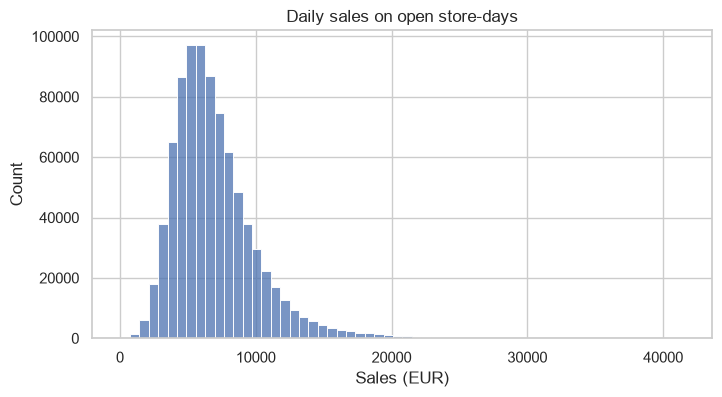

count    844338.0
mean       6956.0
std        3103.8
min          46.0
25%        4859.0
50%        6369.0
75%        8360.0
max       41551.0
Name: sales, dtype: float64

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df.sales, bins=60, ax=ax)
ax.set_title("Daily sales on open store-days")
ax.set_xlabel("Sales (EUR)")
plt.show()
df.sales.describe().round(1)

### Promo, weekday, and store type

These are the strongest operational levers. A promo day averages about **€8,229** vs **€5,930** without — a +38.7% lift.

In [4]:
print("Promo")
print(df.groupby("promo").sales.agg(["mean", "median", "count"]).round(1))
print("\nDay of week (0=Monday)")
print(df.groupby("day_of_week").sales.mean().round(1).to_string())
print("\nStore type")
print(df.groupby("store_type", observed=True).sales.mean().round(1).to_string())

Promo
         mean  median   count
promo                        
0      5929.8  5459.0  467463
1      8228.7  7650.0  376875

Day of week (0=Monday)
day_of_week
0    8216.3
1    7088.4
2    6728.8
3    6768.2
4    7073.0
5    5875.1
6    8224.7

Store type
store_type
a     6925.7
b    10233.4
c     6933.1
d     6822.3


### Seasonality

December is the peak month; February is the trough. This is why the split is temporal and why `month` and `days_to_christmas` are features.

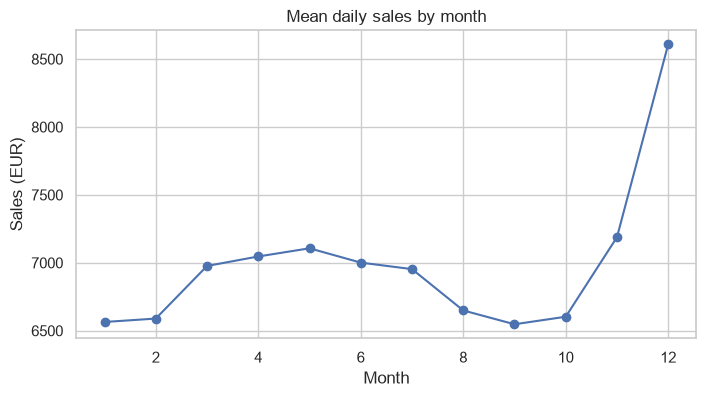

month
1     6564.3
2     6589.5
3     6976.8
4     7046.7
5     7106.8
6     7001.4
7     6953.6
8     6649.2
9     6547.5
10    6603.0
11    7188.6
12    8609.0
Name: sales, dtype: float64

In [5]:
monthly = df.groupby("month").sales.mean()
fig, ax = plt.subplots(figsize=(8, 4))
monthly.plot(marker="o", ax=ax)
ax.set_title("Mean daily sales by month")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (EUR)")
plt.show()
monthly.round(1)

### Missing store metadata

`competition_open_months` and `promo2_open_months` are missing for stores that never had a competitor / never joined Promo2. XGBoost handles missing values natively; the linear model imputes the median.

In [6]:
df[["competition_distance", "competition_open_months", "promo2_open_months"]].isna().mean().round(3)

competition_distance       0.003
competition_open_months    0.318
promo2_open_months         0.501
dtype: float64

## 2. Temporal split and baseline

The test month is touched once. A store-median baseline is the number to beat.

In [7]:
train = df[df.split == "train"]
validation = df[df.split == "validation"]
test = df[df.split == "test"]

X_train, y_train = train[FEATURES], train["sales"]
X_validation, y_validation = validation[FEATURES], validation["sales"]
X_test, y_test = test[FEATURES], test["sales"]

from train import regression_metrics, store_median_baseline

baseline_validation = store_median_baseline(train, validation)
baseline_test = store_median_baseline(train, test)
print("baseline validation", {k: round(v, 2) for k, v in regression_metrics(y_validation, baseline_validation).items()})
print("baseline test      ", {k: round(v, 2) for k, v in regression_metrics(y_test, baseline_test).items()})

baseline validation {'rmse': 2272.87, 'mae': 1654.12, 'r2': 0.52}
baseline test       {'rmse': 1776.75, 'mae': 1333.44, 'r2': 0.63}


## 3. Model comparison and tuning

The canonical run is `train.py`; the cells below reproduce the comparison. Ridge is the linear model, Random Forest is the bagging benchmark, and XGBoost is the boosted model. Ridge's alpha and XGBoost's depth/learning-rate were tuned on the validation month.

In [8]:
from train import linear_pipeline, tree_pipeline, xgb_model

ridge = linear_pipeline(alpha=0.1)
ridge.fit(X_train, y_train)
ridge_validation = ridge.predict(X_validation)
print("Ridge validation", {k: round(v, 2) for k, v in regression_metrics(y_validation, ridge_validation).items()})

Ridge validation {'rmse': 1437.54, 'mae': 1009.24, 'r2': 0.81}


In [9]:
best_xgb = {"max_depth": 8, "learning_rate": 0.1, "subsample": 0.8, "colsample_bytree": 0.8}
xgb = xgb_model(n_estimators=108, early_stopping=False, **best_xgb)
xgb.fit(X_train, y_train, verbose=False)
xgb_validation = xgb.predict(X_validation)
print("XGBoost validation", {k: round(v, 2) for k, v in regression_metrics(y_validation, xgb_validation).items()})
print("XGBoost test      ", {k: round(v, 2) for k, v in regression_metrics(y_test, xgb.predict(X_test)).items()})

XGBoost validation {'rmse': 921.53, 'mae': 644.19, 'r2': 0.92}
XGBoost test       {'rmse': 934.49, 'mae': 672.94, 'r2': 0.9}


### What the training script recorded

`models/model_metadata.json` keeps the full comparison and the tuning table. The table below is the **train-only** comparison used for model selection; the final refit on train + validation scores **936.59 RMSE** on the test month (the error analysis below uses that final model).

In [10]:
metadata = json.loads(Path("models/model_metadata.json").read_text())

rows = []
for name, result in metadata["metrics"]["all_models"].items():
    rows.append({
        "model": name,
        "validation_rmse": result["validation"]["rmse"],
        "validation_mae": result["validation"]["mae"],
        "test_rmse": result["test"]["rmse"],
        "test_mae": result["test"]["mae"],
        "test_r2": result["test"]["r2"],
    })
pd.DataFrame(rows).round(2)

,model,validation_rmse,validation_mae,test_rmse,test_mae,test_r2
0,baseline,2272.87,1654.12,1776.75,1333.44,0.63
1,ridge,1437.54,1009.24,1341.70,1009.74,0.79
2,random_forest,1946.86,1379.66,1835.96,1350.76,0.61
3,xgboost,921.53,644.19,934.49,672.94,0.90


In [11]:
tuning = pd.DataFrame(metadata["metrics"]["all_models"]["xgboost"]["tuning"])
tuning.round(2)

,max_depth,learning_rate,subsample,colsample_bytree,best_iteration,validation_rmse
0,6,0.05,0.8,0.8,553,944.76
1,8,0.05,0.8,0.8,465,922.50
2,10,0.05,0.8,0.8,224,975.33
3,8,0.03,0.8,0.8,554,940.16
4,8,0.10,0.8,0.8,108,921.53
5,6,0.10,0.9,0.7,183,941.27


## 4. What drives the forecast?

XGBoost's impurity importance is a first look. It rewards features used for many splits, so it is descriptive, not causal.

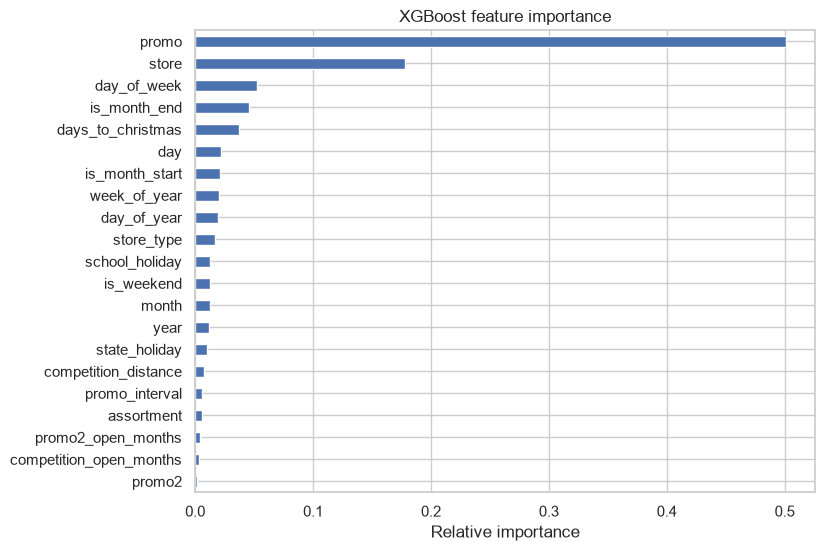

promo                0.501
store                0.178
day_of_week          0.052
is_month_end         0.046
days_to_christmas    0.037
day                  0.022
is_month_start       0.021
week_of_year         0.020
dtype: float32

In [12]:
final_model = joblib.load("models/model.joblib")
importance = pd.Series(final_model.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
importance.plot.barh(ax=ax)
ax.set_title("XGBoost feature importance")
ax.set_xlabel("Relative importance")
plt.show()
importance.sort_values(ascending=False).round(3).head(8)

## 5. Error analysis

Where does the model miss? Store type and weekday are useful slices: if one slice is much worse, the forecast should not be used there without a caveat.

In [13]:
test = test.copy()
test["prediction"] = final_model.predict(X_test)
test["abs_error"] = (test["sales"] - test["prediction"]).abs()
test["error"] = test["sales"] - test["prediction"]

print("test RMSE", round(float(np.sqrt(np.mean(test.error**2))), 2))
print("test MAE ", round(float(test.abs_error.mean()), 2))
print("\nMAE by store type")
print(test.groupby("store_type", observed=True)["abs_error"].mean().round(1).to_string())
print("\nMAE by day of week")
print(test.groupby("day_of_week")["abs_error"].mean().round(1).to_string())

test RMSE 936.59
test MAE  677.6

MAE by store type
store_type
a    685.0
b    890.8
c    665.2
d    658.2

MAE by day of week
day_of_week
0     686.5
1     544.0
2     652.7
3     758.8
4     655.6
5     743.4
6    1228.4


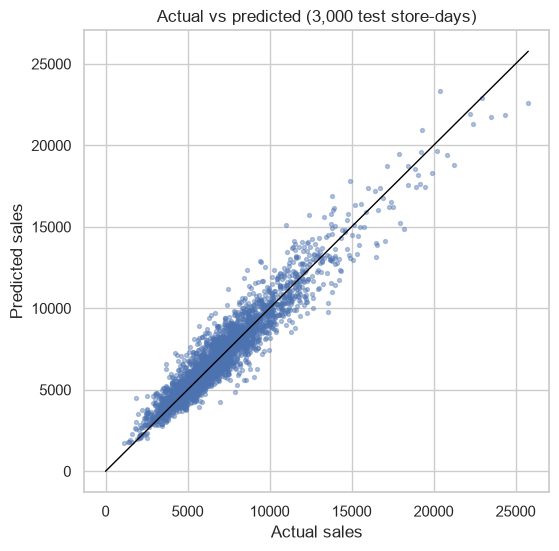

In [14]:
fig, ax = plt.subplots(figsize=(6, 6))
sample = test.sample(3000, random_state=42)
ax.scatter(sample["sales"], sample["prediction"], s=8, alpha=0.4)
limit = max(sample["sales"].max(), sample["prediction"].max())
ax.plot([0, limit], [0, limit], color="black", linewidth=1)
ax.set_xlabel("Actual sales")
ax.set_ylabel("Predicted sales")
ax.set_title("Actual vs predicted (3,000 test store-days)")
plt.show()

## 6. Conclusions

- **XGBoost wins** on the future month: **936.59 RMSE / 677.60 MAE / 0.898 R²**, a 47% RMSE reduction vs the store-median baseline.
- **Promo and weekday are the strongest levers**; December is the seasonal peak.
- **Ridge is a strong linear baseline** (1,341.70 test RMSE). The random forest underperforms because the store ID is high-cardinality and the structure is largely additive; XGBoost's native categorical handling fixes it.
- **The test month is one month.** A rolling-origin backtest over 6–12 months would give a more stable generalization estimate.

**Next steps:** closed-day classifier, weather/external data, quantile intervals, cloud deployment, and drift monitoring. The serving path is `predict.py` → Docker; see the README.